In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#Grafikleri Jupyter içinde düzgün görünmesi için
%matplotlib inline

In [4]:
# Superstore veri setini hafızaya yüklüyoruz
df= pd.read_csv('train.csv')

In [7]:
# 1.Künye ve Boyut Kontrolü
print("---VERİ BOYUTU (Satır , Sütun)---")
print(df.shape) 

print("\n---İNFO RAPORU ---")
print(df.info())

print("\n--- EKSİK VERİ SAYILARI---")
print(df.isna().sum())

print("\n--- TEKRARLI SATIR SAYISI ---")
print(df.duplicated().sum())

---VERİ BOYUTU (Satır , Sütun)---
(9800, 18)

---İNFO RAPORU ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub-Category   9800 non-null   object 
 16  Product Name   9800 non-null   

<Figure size 800x400 with 0 Axes>

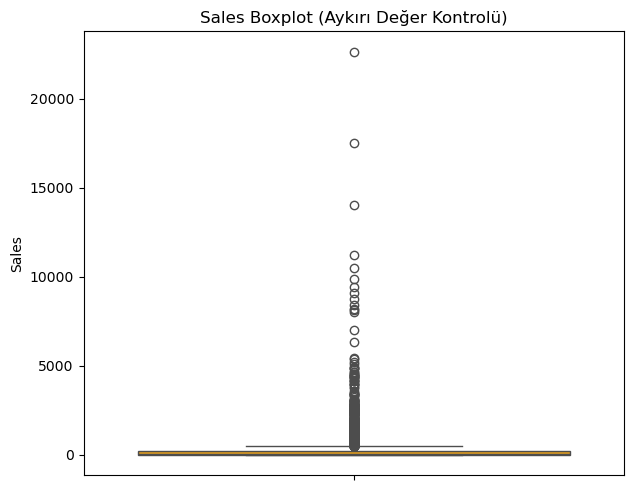

C:\Users\OEM\AppData\Local\Temp\ipykernel_22944\1213723915.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Category', data=df, palette='Set2')


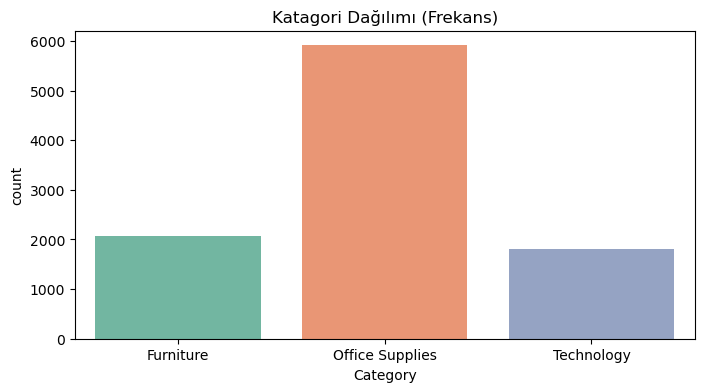

In [11]:
#Sayısal değişşken (Sales) için Histogram ve Boxplot
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['Sales'], color='orange')
plt.title('Sales Boxplot (Aykırı Değer Kontrolü)')

plt.tight_layout()
plt.show()

#Kategori değişken (Category) için Frekans Dağılımı
plt.figure(figsize=(8, 4))
sns.countplot(x='Category', data=df, palette='Set2')
plt.title('Katagori Dağılımı (Frekans)')
plt.show()

C:\Users\OEM\AppData\Local\Temp\ipykernel_22944\1939626755.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Category', y='Sales', data=df, estimator=sum, palette='viridis')


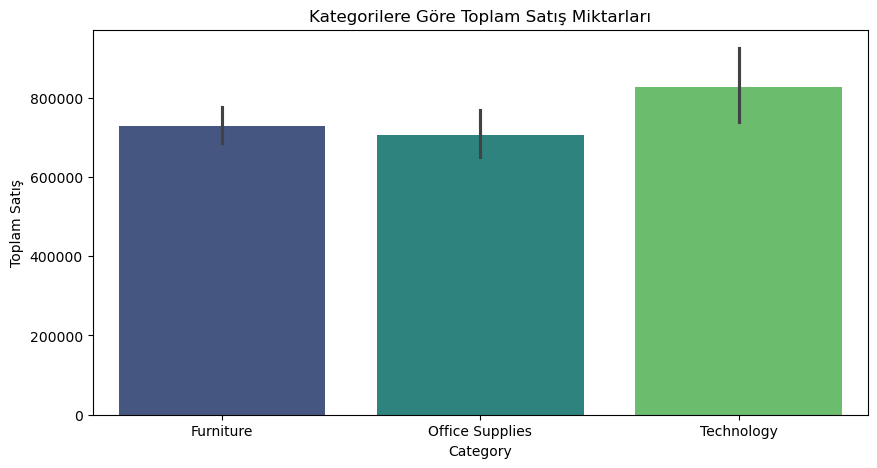

C:\Users\OEM\AppData\Local\Temp\ipykernel_22944\1939626755.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Segment', y='Sales', data=df, palette='Set3')


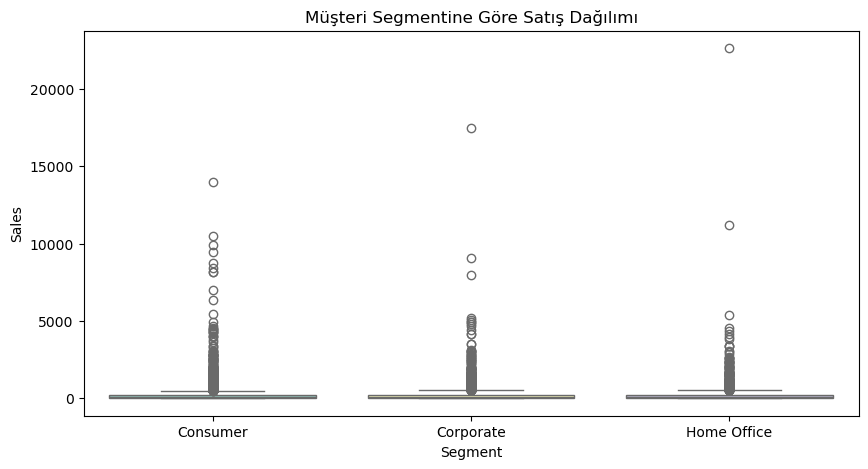

In [12]:
# Kategori bazlı toplam satışları inceleyelim (Kategorik - Sayısal )
plt.figure(figsize=(10, 5))
sns.barplot(x='Category', y='Sales', data=df, estimator=sum, palette='viridis')
plt.title('Kategorilere Göre Toplam Satış Miktarları')
plt.ylabel('Toplam Satış')
plt.show()

# Segmentlere göre satış dağılımına boxplot ile bakalım
plt.figure(figsize=(10, 5))
sns.boxplot(x='Segment', y='Sales', data=df, palette='Set3')
plt.title('Müşteri Segmentine Göre Satış Dağılımı')
plt.show()

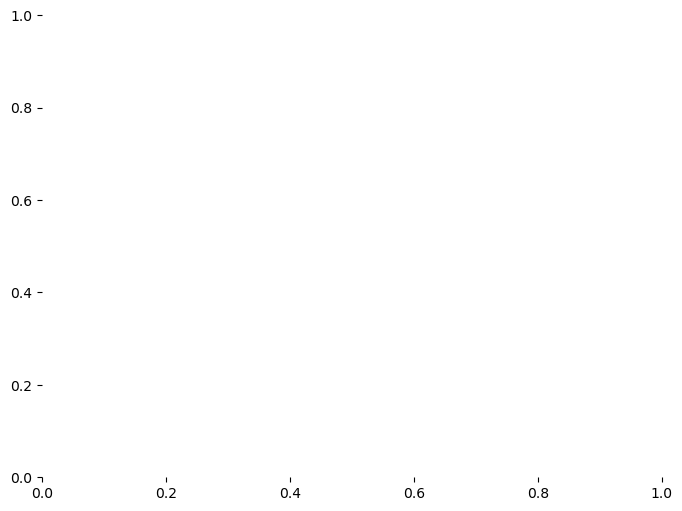

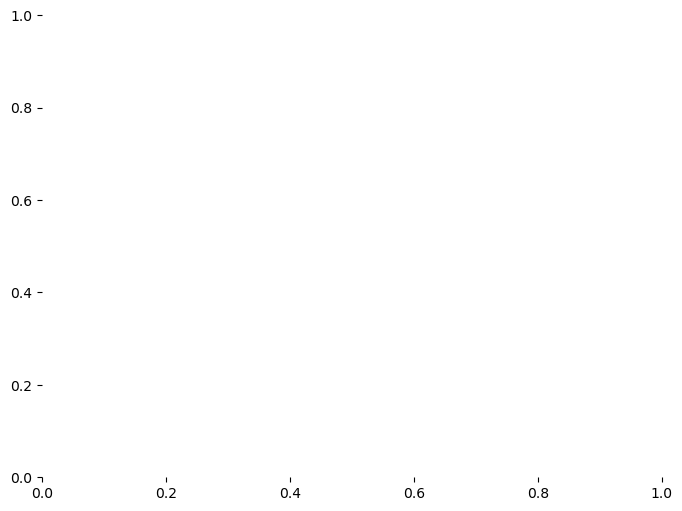

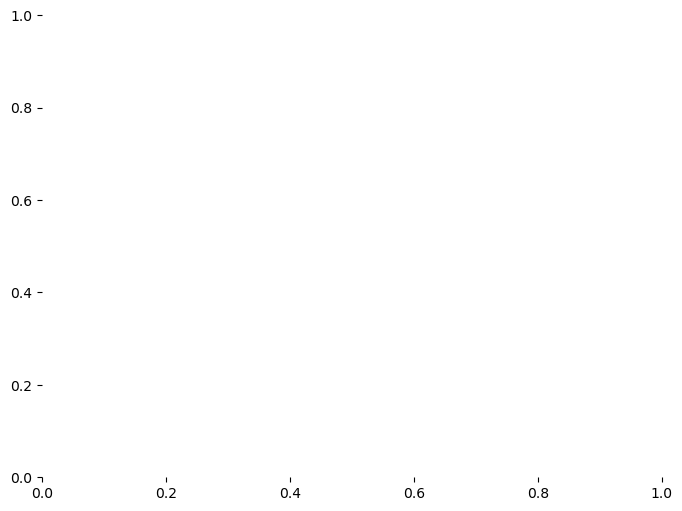

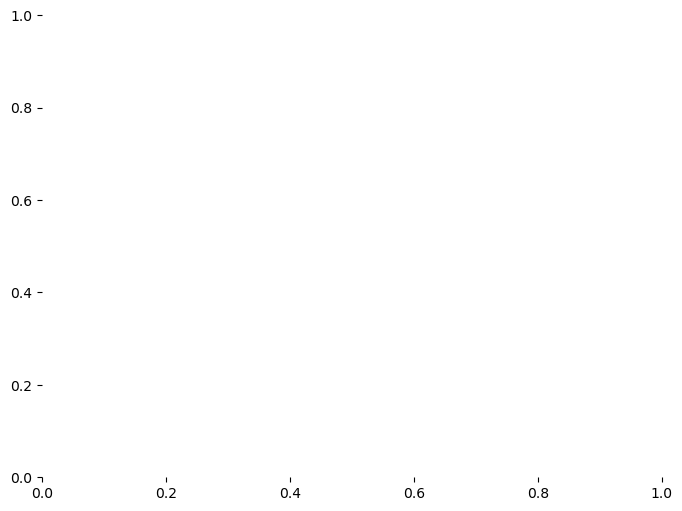

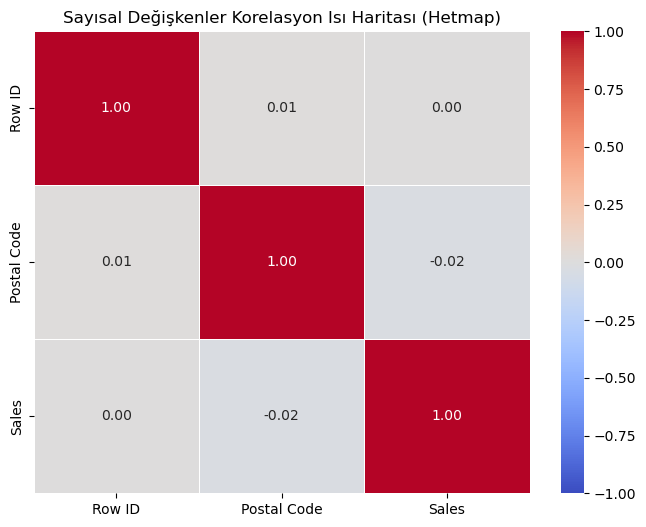

In [18]:
# Sadece sayısal sütunları seçerek korelasyon matrisini çıkarıyoruz
numeric_df = df.select_dtypes(include=['float64', 'int64'])
corr_matrix = numeric_df.corr()

# Isı haritası (Heatmap) ile görseleştiriyoruz
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title('Sayısal Değişkenler Korelasyon Isı Haritası (Hetmap)')
plt.show()


Verinin Künyesi: 9800 satır, 18 sütun ve sıfır tekrarlı kayıtla tertemiz bir set üzerinden çalışıldı.

Kategori Analizi: Office Supplies adet olarak en çok satan kategori iken, toplam ciroda (satış miktarında) Technology açık ara zirvede yer aldı.

Dağılım ve Aykırılıklar: Satış (Sales) dağılımında sağa çarpıklık ve büyük hacimli siparişlerden kaynaklanan aykırı değerler (outliers) gözlemlendi.